# Plantilla: filtro de Kalman extendido con estado aumentado

Plantilla mínima para la entrega 3 de Modelación Experimental. Corre de principio a fin con un ejemplo (un SIR continuo con datos sintéticos) y está escrita para que solo haya que cambiar las secciones marcadas con **CAMBIAR**: el modelo, los parámetros de la entrega 2 y los datos.

Las funciones están en `ekf_plantilla.py`: `ekf_correr` (el filtro), `jacobiano_num` (jacobianos por diferencias finitas), `paso_rk4` (un paso de un modelo continuo), `cond_observabilidad` (rango y número de condición) y `autocorr_innov` (prueba de blancura). La versión de MATLAB hace lo mismo y da los mismos números.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ekf_plantilla import ekf_correr, paso_rk4, cond_observabilidad, autocorr_innov

## 1. Modelo (CAMBIAR)

Escriba el modelo de la entrega 2. Si es continuo, `g` es el lado derecho $dx/dt = g(x,p)$ y `paso_rk4` lo integra entre muestras; si es discreto, escriba directamente el paso $x(k+1) = f(x(k),p)$ en `paso`. La medición $h(x,p)$ es la variable que se comparó con los datos en la entrega 2.

Ejemplo: SIR normalizado, $\dot s = -\beta s i$, $\dot i = \beta s i - \gamma i$, y se mide $i$.

In [2]:
nombres_x = ["s", "i"]
nombres_p = ["beta", "gamma"]
g = lambda x, p: np.array([-p[0] * x[0] * x[1], p[0] * x[0] * x[1] - p[1] * x[1]])
h = lambda x, p: x[1]
Ts = 1.0                                       # periodo de muestreo de los datos (días)
paso = lambda x, p: paso_rk4(g, x, p, Ts, 10)  # modelo discreto: x(k+1) = paso(x(k), p)

## 2. Parámetros de la entrega 2 (CAMBIAR)

`p_est` son los parámetros estimados en la entrega 2 e `ic_p` sus intervalos de confianza del 95 % del bootstrap. `idx` dice qué parámetros estima el filtro (al menos uno; índices desde 0); los demás quedan fijos en `p_est`.

In [3]:
p_est = np.array([0.45, 0.2])
ic_p = np.array([[0.38, 0.55], [0.17, 0.23]])
idx = [0]                                      # el filtro estima beta
x0 = np.array([0.999, 0.001])                  # estado inicial del modelo

## 3. Datos (CAMBIAR)

Un CSV con el tiempo `t` y la medición `y`. Si se conocen los estados verdaderos (datos sintéticos), van en columnas con los nombres de `nombres_x` y se dibujan como referencia; con datos reales no existen.

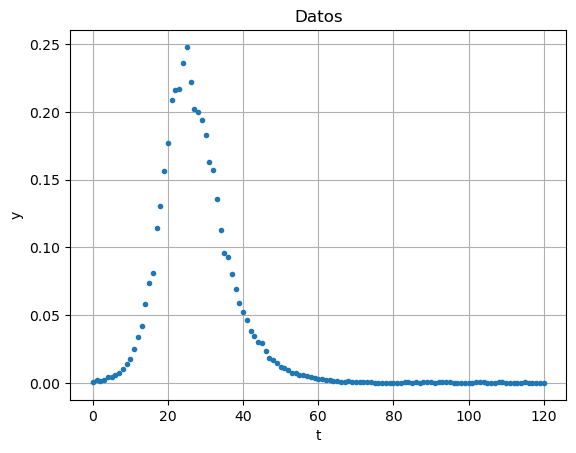

In [4]:
datos = pd.read_csv("../ejemplo_datos.csv")
t = datos["t"].to_numpy()
y = datos["y"].to_numpy()
hay_verdad = all(c in datos.columns for c in nombres_x)
plt.plot(t, y, ".")
plt.xlabel("t"); plt.ylabel("y"); plt.title("Datos"); plt.grid(True); plt.show()

## 4. Modelo aumentado

El estado aumentado es $x_a = [x;\ \theta]$, con $\theta = p[\text{idx}]$ y $\theta(k+1) = \theta(k)$. No hay que cambiar nada aquí.

In [5]:
nx, nt = x0.size, len(idx)

def con_theta(theta):
    p = p_est.copy(); p[idx] = theta
    return p

fa = lambda xa: np.concatenate([paso(xa[:nx], con_theta(xa[nx:])), xa[nx:]])
ha = lambda xa: h(xa[:nx], con_theta(xa[nx:]))
nombres_xa = nombres_x + [nombres_p[i] for i in idx]

## 5. Observabilidad: número de condición

Se linealiza a lo largo de una simulación con los parámetros de la entrega 2 y en cada instante se arma $\mathcal{O}(k) = [H;\ HF;\ HF^2;\ \dots]$ con tantas mediciones como estados aumentados. Las columnas se escalan por la magnitud típica de cada estado (`escala`). Un número de condición alto significa que alguna combinación de estados casi no se ve en las mediciones: su banda tarda en cerrarse.

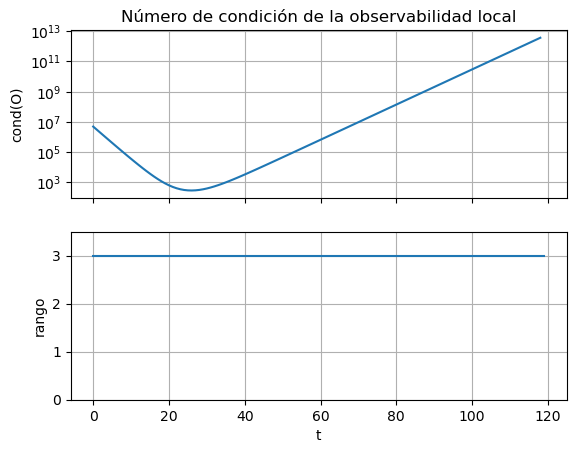

In [6]:
N = t.size
X_nom = np.zeros((nx + nt, N)); X_nom[:, 0] = np.concatenate([x0, p_est[idx]])
for k in range(N - 1):
    X_nom[:, k + 1] = fa(X_nom[:, k])
escala = np.abs(X_nom).max(axis=1)             # CAMBIAR si conviene otra escala
obs = cond_observabilidad(X_nom, fa, ha, nx + nt, escala)
fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].semilogy(t, obs["cond"]); ax[0].set_ylabel("cond(O)"); ax[0].grid(True)
ax[0].set_title("Número de condición de la observabilidad local")
ax[1].step(t, obs["rango"], where="post"); ax[1].set_ylim(0, nx + nt + 0.5)
ax[1].set_ylabel("rango"); ax[1].set_xlabel("t"); ax[1].grid(True); plt.show()

## 6. Configuración del filtro (CAMBIAR)

- $R$: varianza del ruido de medición. Use la de los residuales del mejor ajuste de la entrega 2 (aquí, un ruido relativo del 5 %).
- $P(0)$: para $\theta$, una desviación de un cuarto del ancho del intervalo del bootstrap; para los estados, según qué tan bien se conoce la condición inicial.
- $Q$: ruido de proceso. El de $\theta$ dice qué tan rápido puede cambiar el parámetro; en la sección 8 se comparan varios valores.

In [7]:
R = lambda xa: (0.05 * max(ha(xa), 0) + 5e-4) ** 2
xa0 = np.concatenate([x0, p_est[idx]])
P0 = np.diag(np.concatenate([[1e-3, 1e-3], (ic_p[idx, 1] - ic_p[idx, 0]) / 4]) ** 2)
qX = np.array([1e-4, 1e-4])                    # desviación diaria del ruido de los estados
qT = 1e-3 * np.ones(nt)                        # desviación diaria del ruido de los parámetros
Q = np.diag(np.concatenate([qX, qT]) ** 2)
lb = np.zeros(nx + nt)                         # fracciones y tasas no negativas

## 7. Correr el filtro

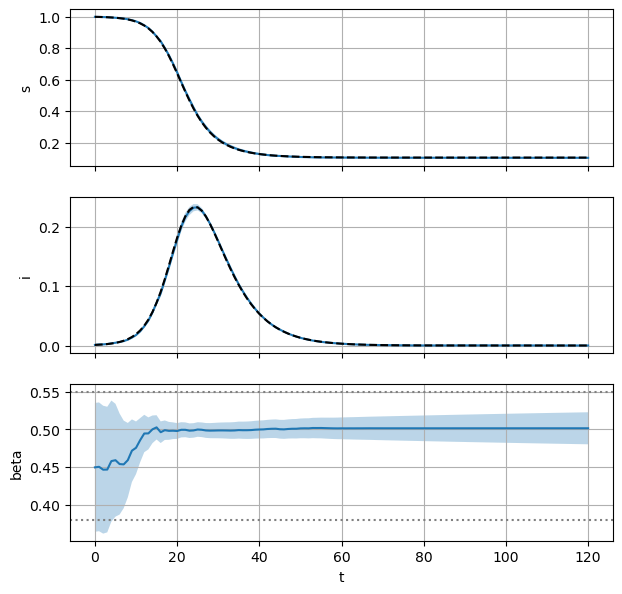

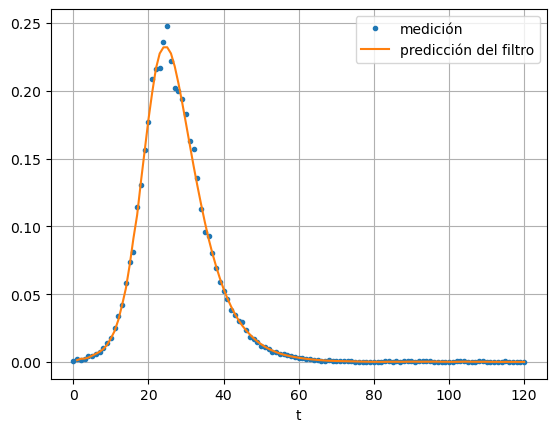

In [8]:
est = ekf_correr(y, fa, ha, xa0, P0, Q, R, lb)
fig, ax = plt.subplots(nx + nt, 1, sharex=True, figsize=(7, 2.3 * (nx + nt)))
for c in range(nx + nt):
    xc, sc = est["x"][c], est["sd"][c]
    ax[c].fill_between(t, xc - 2 * sc, xc + 2 * sc, alpha=0.3)
    ax[c].plot(t, xc)
    if c < nx and hay_verdad:
        ax[c].plot(t, datos[nombres_x[c]], "k--")
    if c >= nx:
        for v in ic_p[idx[c - nx]]:
            ax[c].axhline(v, ls=":", color="gray")
    ax[c].set_ylabel(nombres_xa[c]); ax[c].grid(True)
ax[-1].set_xlabel("t"); plt.show()

plt.plot(t, y, ".", label="medición"); plt.plot(t, est["yhat"][0], label="predicción del filtro")
plt.legend(); plt.xlabel("t"); plt.grid(True); plt.show()

### Traza de $P$ y norma de la ganancia

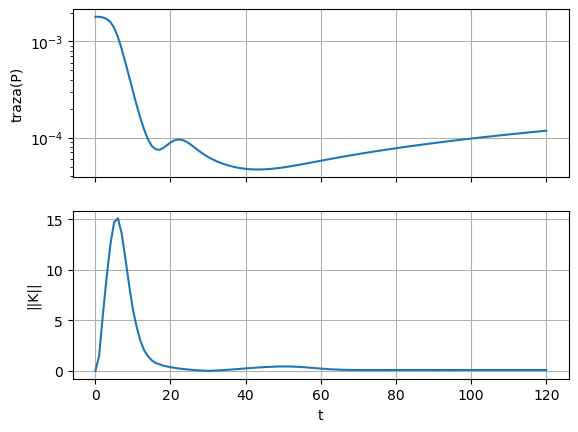

In [9]:
fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].semilogy(t, est["trP"]); ax[0].set_ylabel("traza(P)"); ax[0].grid(True)
ax[1].plot(t, est["normK"]); ax[1].set_ylabel("||K||"); ax[1].set_xlabel("t"); ax[1].grid(True)
plt.show()

### Prueba de blancura de las innovaciones

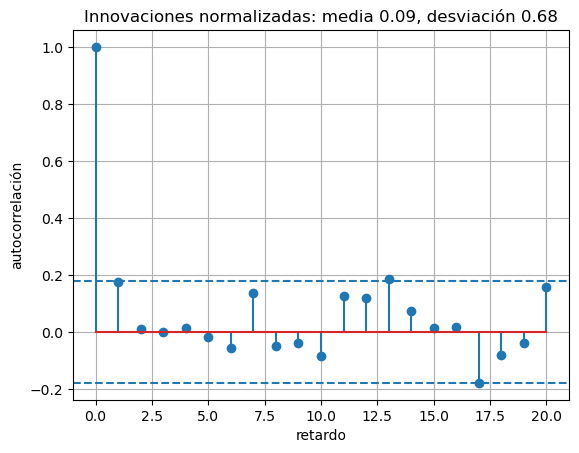

In [10]:
z = est["z"][0]
r, lags, lim = autocorr_innov(z, 20)
plt.stem(lags, r); plt.axhline(lim, ls="--"); plt.axhline(-lim, ls="--")
plt.xlabel("retardo"); plt.ylabel("autocorrelación"); plt.grid(True)
plt.title(f"Innovaciones normalizadas: media {np.nanmean(z):.2f}, desviación {np.nanstd(z, ddof=1):.2f}")
plt.show()

## 8. Efecto de $Q$ sobre el parámetro

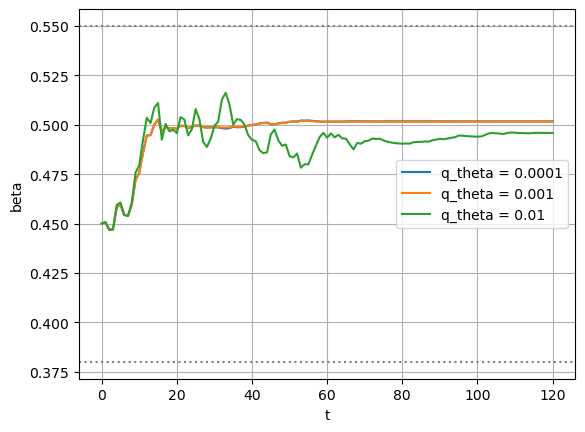

In [11]:
for q in [1e-4, 1e-3, 1e-2]:
    e = ekf_correr(y, fa, ha, xa0, P0, np.diag(np.concatenate([qX, q * np.ones(nt)]) ** 2), R, lb)
    plt.plot(t, e["x"][nx], label=f"q_theta = {q:g}")
for v in ic_p[idx[0]]:
    plt.axhline(v, ls=":", color="gray")
plt.legend(); plt.xlabel("t"); plt.ylabel(nombres_xa[nx]); plt.grid(True); plt.show()

Valores finales (para comparar con la versión de MATLAB):

In [12]:
pd.DataFrame({"estado": nombres_xa, "estimación final": est["x"][:, -1], "2 sigma": 2 * est["sd"][:, -1]})

,estado,estimación final,2 sigma
0,s,0.105789,0.004953
1,i,0.000020,0.000327
2,beta,0.501552,0.021136
